# Construcción y evaluación de un sistema de recuperación

Buscar literatura científica no consiste solo en encontrar textos parecidos a una pregunta. El sistema debe recuperar documentos útiles, ordenarlos bien y responder con un coste y una latencia asumibles.

Este trabajo construye una base documental real con TREC-COVID y compara configuraciones mediante **experimentos offline pareados**. Pinecone almacena los vectores y ejecuta las búsquedas. OpenAI y, opcionalmente, Qwen producen las representaciones. La configuración ganadora no está decidida de antemano: tendrá que justificar su calidad, latencia, almacenamiento y complejidad.


## 1. La decisión que queremos tomar

Imaginemos una búsqueda sobre las manifestaciones neurológicas de COVID-19. Un resultado puede compartir muchas palabras con la pregunta y no responderla; otro puede aportar evidencia pertinente utilizando vocabulario diferente. La coincidencia léxica y la proximidad semántica capturan señales distintas. Por eso necesitamos comparar resultados contra juicios de relevancia, no elegir por el aspecto del vector o por la reputación del modelo.

La pregunta operativa es: **¿qué configuración devuelve los mejores diez documentos para este conjunto de consultas, sin exceder nuestro presupuesto de latencia?** El número diez expresa la parte visible del ranking que nos importa. No impone cuántos candidatos debe recuperar cada componente antes de construir ese ranking.

“Offline” significa que utilizamos consultas y relevancias ya recogidas, sin repartir tráfico entre usuarios. **No significa sin Internet ni sin servicios externos.** En cada experimento enviamos las mismas consultas a distintas configuraciones de Pinecone y contrastamos los IDs devueltos con los mismos juicios. Un A/B online posterior podría medir comportamiento real; aquí medimos calidad de recuperación.

El recorrido tiene cuatro momentos conectados:

1. Entender los documentos y fijar qué contará como una respuesta relevante.
2. Construir una referencia léxica en Pinecone y comprobar resultados concretos.
3. Cambiar modelo, dimensión, profundidad y combinación de señales, manteniendo lo demás controlado.
4. Elegir en desarrollo, congelar la elección y comprobarla en una reserva final.

El notebook concentra las decisiones y sus interpretaciones. Las operaciones repetitivas viven en cinco archivos contiguos: `retrieval_core.py` contiene el protocolo y las métricas; `embedding_providers.py`, los adaptadores y la caché; `retrieval_backends.py`, los índices y las búsquedas; `retrieval_reporting.py`, las comparaciones; y `retrieval_runtime.py`, la concurrencia, las cuotas y los reintentos. No hay carpeta `src/` ni un servicio productivo oculto detrás de las celdas.


In [1]:
from pathlib import Path
import os
import sys
from dataclasses import asdict

project_root = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "src" / "retrieval_lab").is_dir()
)
source_path = str(project_root / "src")
if source_path not in sys.path:
    sys.path.insert(0, source_path)
os.chdir(project_root)

import pandas as pd
pd.options.display.float_format = "{:,.2f}".format
from IPython.display import display, Markdown
from langchain_core.documents import Document

from retrieval_lab.configuration.settings import ExperimentConfig
from retrieval_lab.configuration.environment import configure, check_credentials
from retrieval_lab.data.corpus import load_trec_covid, document_text, prepare_text
from retrieval_lab.infrastructure.artifacts import fingerprint
from retrieval_lab.evaluation.design import Arm, experiment_arms, make_query_split, model_plan
from retrieval_lab.evaluation.metrics import evaluate_ranking
from retrieval_lab.evaluation.statistics import paired_bootstrap
from retrieval_lab.representations.cache import EmbeddingCache
from retrieval_lab.storage.pinecone import PineconeWorkspace
from retrieval_lab.retrieval.lab import RetrievalLab
from retrieval_lab.evaluation.runner import run_experiments
from retrieval_lab.evaluation.selection import freeze_decision
from retrieval_lab.reporting.views import (
    corpus_overview, relevance_profile, show_results,
    controlled_comparisons, depth_and_hybrid, inspect_query, error_analysis,
    select_candidate, final_report,
)


In [2]:
config = ExperimentConfig(
    include_qwen=False,
    candidate_depths=(20, 50, 100),
    comparison_depth=50,
    reference_dimension=768,
    latency_budget_ms=1500,
    quality_tolerance=0.01,
)
display(configure(config))


,Python,Semilla,Corpus,Artefactos
0,3.14.5,42,data,artifacts/pinecone_v1


## 2. Antes de comparar modelos: ¿qué estamos buscando?

TREC-COVID, distribuido por BEIR, contiene aproximadamente 171.000 documentos científicos, 50 consultas y juicios de relevancia. Es un benchmark de recuperación, no una colección de preguntas con una única respuesta correcta. Una consulta puede tener centenares de documentos relevantes.

Tres piezas cumplen funciones diferentes. El **corpus** contiene documentos identificados por un ID estable. Las **consultas** contienen las necesidades de información. Los **qrels** vinculan un ID de consulta y uno de documento con un grado de relevancia. El buscador solo utiliza corpus y consulta; los qrels se consultan después para evaluar. No se introducen como metadatos en Pinecone ni se utilizan para fabricar embeddings.

Cargaremos el corpus completo. Si ya está en `data/trec-covid/`, se reutiliza; si no, se descarga. Los artefactos de esta implementación se guardan en `artifacts/pinecone_v1/`, con cachés identificadas por su contenido y resultados agrupados por la huella del protocolo. Repetir el mismo protocolo puede actualizar sus archivos de resultados; no crea necesariamente una carpeta nueva.

La unidad recuperada será **un documento**, representado por título y texto. Esto permite comparar directamente sus IDs con los qrels. Antes de enviar contenido a los proveedores, aplicamos un límite común de 6.000 bytes UTF-8 al principio del texto. Es una decisión conservadora de ejecución, no una afirmación de que ese tamaño sea óptimo: evita que cada proveedor recorte una cantidad diferente de contenido y deja margen para sus instrucciones. Bytes no significa tokens.

La siguiente salida cuantifica cuántos documentos quedan recortados. Si la proporción o los errores posteriores indican pérdida de evidencia, habrá motivo para un experimento separado de fragmentación. **No cambiamos simultáneamente chunking y modelo:** de hacerlo, una diferencia de calidad no tendría una explicación clara. Las conclusiones de este protocolo quedan condicionadas a esta representación común.


In [3]:
corpus, queries, qrels, dataset_signature = load_trec_covid(config)
dev_ids, holdout_ids = make_query_split(queries, qrels, config)
document_ids = sorted(corpus)
texts = [prepare_text(document_text(corpus[d]), config.text_max_bytes) for d in document_ids]
prepared_queries = {q: prepare_text(t, config.text_max_bytes) for q, t in queries.items()}
data_signature = fingerprint({"dataset": dataset_signature, "text_max_bytes": config.text_max_bytes})
shortened_count = corpus_overview(
    corpus, queries, qrels, dev_ids, holdout_ids, texts, config,
)


,Documentos,Consultas,Juicios,Desarrollo,Reserva final
0,171332,50,66336,30,20


,Bytes UTF-8 por documento
count,"171,332.00"
mean,"1,120.70"
std,937.40
min,0.00
50%,"1,177.00"
95%,"2,324.00"
99%,"3,019.00"
max,"122,591.00"


**104 documentos (0.06%)** superan el límite común de 6,000 bytes. Se conserva el comienzo del título y del texto; el límite es idéntico para todos los modelos.

In [4]:
examples = [
    Document(page_content=texts[i], metadata={"document_id": d, "title": corpus[d]["title"]})
    for i, d in enumerate(document_ids[:3])
]
display(pd.DataFrame([
    {"ID": d.metadata["document_id"], "Título": d.metadata["title"], "Texto": d.page_content[:600]}
    for d in examples
]))


,ID,Título,Texto
0,0002xs6a,The Father-Daughter Dinner Dance: A Waltz With...,The Father-Daughter Dinner Dance: A Waltz With...
1,000ahtxm,Epidemiological and clinical characteristics o...,Epidemiological and clinical characteristics o...
2,000ajevz,Late‐onset Pneumocystis jirovecii pneumonia po...,Late‐onset Pneumocystis jirovecii pneumonia po...


## 3. El contrato de evaluación: qué significa mejorar

Reservamos 30 consultas para desarrollo y 20 para la comprobación final. La separación es reproducible y aproximadamente estratificada por cantidad de documentos relevantes: evitamos que todas las preguntas con pocas respuestas queden por azar en el mismo grupo. Sus IDs y la huella de los qrels se guardan en disco.

En desarrollo podremos observar fallos, comparar alternativas y elegir parámetros. En la reserva final evaluaremos únicamente las configuraciones ya elegidas. Si miramos sus resultados y volvemos a ajustar, deja de ser una reserva independiente. Mantener una semilla fija no corrige esa contaminación.

Para las métricas binarias consideramos relevante todo documento con grado mayor que cero. Para nDCG conservamos el grado original y usamos ganancia lineal: un grado 2 aporta el doble de ganancia que un grado 1 antes del descuento por posición. Un documento sin juicio recibe ganancia cero para el cálculo, **pero “sin juicio” no demuestra “irrelevante”**. Por eso también se registra la fracción juzgada entre los diez primeros.

| Medida | Pregunta que responde | Cómo se calcula |
|---|---|---|
| Precision@10 | ¿Qué proporción de las diez posiciones es relevante? | Relevantes recuperados en esas posiciones / 10. |
| Recall normalizado@k | ¿Qué fracción del máximo de relevantes recuperables con este k hemos conseguido? | Relevantes entre los primeros k / min(k, relevantes conocidos de la consulta). |
| MRR@10 | ¿Cuánto hay que esperar al primer resultado relevante? | Inverso de su posición; cero si no aparece en las diez primeras. |
| nDCG@10 | ¿Aparecen pronto los documentos de mayor relevancia? | Ganancia descontada por posición / ganancia del orden ideal. |
| MAP@k | ¿Se recuperan relevantes de forma consistente en el ranking? | Media entre consultas de AP@k; AP suma precisiones en posiciones relevantes y divide por todos los relevantes conocidos. |

La medida primaria será **nDCG@10**. Precision y MRR ayudan a interpretar su comportamiento; Recall normalizado mide cuánto aprovechamos el presupuesto de recuperación para encontrar relevantes; no mide la cobertura de todos los relevantes del corpus. Ninguna representa por sí sola la calidad de un sistema completo de generación de respuestas.

Las funciones son explícitas en `retrieval_core.py`. En particular, AP@k divide por todos los relevantes, no por `min(k, relevantes)`; esa convención importa cuando se compara con otra herramienta. Los casos pequeños de cálculo se verifican en `test_retrieval.py`; no sustituyen las relevancias reales del experimento.


### Cómo interpretar la recuperación con un presupuesto limitado

Aquí **k es el máximo de documentos que pedimos recuperar**, mientras que las métricas terminadas en @10 evalúan las primeras diez posiciones. El recall normalizado divide los aciertos entre `min(k, relevantes conocidos)`: con k=100, encontrar 100 relevantes de 400 da 1; encontrar los 78 relevantes de una consulta que tiene 78 también da 1. Si solo encontramos 39 de esos 78, da 0,5. Para consultas sin relevantes conocidos se asigna 0.

Esta medida responde a cuánto hemos conseguido de lo posible con ese presupuesto. Cuando hay al menos k relevantes coincide con Precision@k; cuando hay menos coincide con el recall estándar. El denominador utiliza el k solicitado, aunque el buscador devuelva menos resultados. La tabla siguiente muestra los denominadores que corresponden a nuestras consultas.

Las profundidades configuradas son 20, 50 y 100. Cambiarlas sigue siendo un experimento distinto: afecta al número de candidatos y, en la búsqueda híbrida, a los documentos que pueden participar en la fusión. Normalizar el recall no hace equivalentes esos presupuestos ni garantiza que la métrica aumente al ampliar k. Para aislar modelo y dimensión utilizamos la profundidad común de 50; después estudiamos la profundidad por separado.


,Palabras,Relevantes,Relevantes recuperables@20,Relevantes recuperables@50,Relevantes recuperables@100
count,30.00,30.00,30.00,30.00,30.00
mean,10.53,486.20,20.00,50.00,100.00
std,3.05,221.64,0.00,0.00,0.00
min,5.00,111.00,20.00,50.00,100.00
25%,9.00,289.25,20.00,50.00,100.00
50%,10.50,482.00,20.00,50.00,100.00
75%,11.75,625.00,20.00,50.00,100.00
max,20.00,867.00,20.00,50.00,100.00


,Juicios en desarrollo
Grado,
-1,1
0,25132
1,6160
2,8426


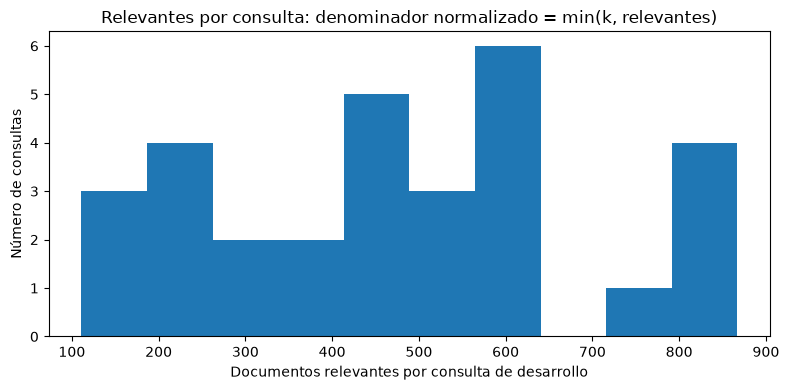

In [5]:
relevance_distribution = relevance_profile(queries, qrels, dev_ids, config)


## 4. Qué se almacenará en Pinecone y por qué

Usamos Pinecone porque el objeto del experimento es una búsqueda sobre una base vectorial gestionada. El portátil prepara representaciones, envía consultas, fusiona listas y calcula métricas. **No hay un índice HNSW, IVF o BM25 local sirviendo como sustituto de Pinecone.** La matriz local de embeddings es una caché para evitar pagar o calcular de nuevo; no es el motor de búsqueda.

Esta elección también delimita el experimento. No podremos barrer libremente `ef_search`, `M`, `nprobe` o product quantization como en una biblioteca de índices. Comparamos controles expuestos a nuestra aplicación: modelo, dimensiones, profundidad y estrategia de recuperación. No hay un “mejor HNSW de Pinecone” que se pueda inferir de estas tablas.

Pinecone fija la dimensión de un índice vectorial denso al crearlo. Por ello crearemos un índice por dimensión: 256, 512 y 768. Dentro de cada uno, un **namespace** identifica los vectores de cada modelo activo. Si habilitamos Qwen, sus vectores se mantienen separados de los de OpenAI: aunque tengan la misma dimensión, pertenecen a espacios distintos y cada consulta debe representarse con el modelo de sus documentos. La huella incluida en el namespace evita reutilizar silenciosamente otro corpus o preprocesamiento.

La referencia léxica utiliza un cuarto índice, sparse, con producto escalar. Calculamos localmente los pesos BM25, los cargamos como vectores dispersos y dejamos que Pinecone los recupere. Para la variante híbrida consultaremos ambos índices y fusionaremos sus listas en la aplicación. Esta separación permite observar cada señal individualmente y reutilizar una sola colección léxica.

Antes de cargar, hay que dimensionar el experimento. Cada matriz densa requiere aproximadamente **N × d × 4 bytes** usando float32. La tabla suma vectores de todas las representaciones: no son documentos nuevos, sino versiones del mismo corpus. Es un mínimo de datos numéricos, no el almacenamiento facturado: faltan índices internos, metadatos y otros gastos del servicio.

El recorrido completo puede superar las cuotas de un plan gratuito. Revise en su cuenta número de índices, namespaces, almacenamiento y uso; disponer de una clave no garantiza capacidad suficiente. Con la configuración predeterminada se utiliza OpenAI y se almacenan tres representaciones densas del mismo corpus. Si se activa Qwen, se añade su cálculo local y otras tres representaciones. Las cachés compatibles se reutilizan. La tabla siguiente calcula las cantidades a partir de los modelos y dimensiones activos; el número de búsquedas depende además de las consultas, estrategias, profundidades y repeticiones. Las tarifas y los límites dependen de cuenta, región y fecha. No se presenta una estimación en euros inventada.


In [6]:
plan = model_plan(config, len(corpus))
display(plan.round(3))
configured_arms = experiment_arms(config)
display(pd.DataFrame([{
    "Modelos activos": len(config.active_models),
    "Representaciones densas": len(plan),
    "Configuraciones densas o híbridas": sum(a.strategy != "lexica" for a in configured_arms),
    "Referencias léxicas": sum(a.strategy == "lexica" for a in configured_arms),
    "Configuraciones totales": len(configured_arms),
    "Índices densos distintos": plan["Dimensiones"].nunique(),
    "Índices sparse": 1,
    "Vectores densos totales": int(plan["Vectores"].sum()),
    "Solo vectores densos (GiB)": plan["Vectores brutos (GiB)"].sum(),
}]).round(3))


,Modelo,Identificador,Dimensiones,Vectores,Vectores brutos (GiB)
0,openai-large,text-embedding-3-large,256,171332,0.16
1,openai-large,text-embedding-3-large,512,171332,0.33
2,openai-large,text-embedding-3-large,768,171332,0.49


,Modelos activos,Representaciones densas,Configuraciones densas o híbridas,Referencias léxicas,Configuraciones totales,Índices densos distintos,Índices sparse,Vectores densos totales,Solo vectores densos (GiB)
0,1,3,18,1,19,3,1,513996,0.98


## 5. Conectar y comprobar: el primer viaje a la base documental

Copie `.env.example` como `.env` y complete localmente las claves de Pinecone y OpenAI. No introduzca secretos en celdas: una salida guardada del notebook podría acabar compartida. `.env` está excluido del control de versiones. La comprobación solo indica qué variables existen; no muestra sus valores.

Las celdas siguientes **sí crean recursos y consumen servicios cuando se ejecutan con credenciales**. Usan el prefijo, la nube y la región de `.env`. El prefijo debe identificar un proyecto de pruebas, no una base productiva. Un índice existente con dimensión, métrica o región incompatibles provoca un error; no se borra ni se reconstruye automáticamente.

Empezamos por BM25. Su representación asigna coordenadas a términos y pesos a los documentos. La frecuencia de un término ayuda, pero con saturación; los términos presentes en muchos documentos aportan menos información, y la longitud documental interviene en la normalización. Se fijan `k1=1.2` y `b=0.75`: son parámetros de referencia, no valores optimizados aquí. La tokenización convierte a minúsculas, retira una lista fija de palabras frecuentes en inglés y conserva términos de dos o más caracteres. Se ajusta con todo el corpus, sin usar qrels.

Una vez terminada la carga, abra [Pinecone](https://app.pinecone.io/), seleccione su proyecto y localice el índice que termina en `-sparse`. Compare el namespace y el número de registros con la tabla. Inspeccione uno de los IDs vistos antes: los metadatos conservan ID, título y un extracto, **no la relevancia**.

La escritura y la disponibilidad para búsqueda no son instantáneas. El helper espera el recuento esperado y comprueba tres registros remotos contra su representación local. Es una comprobación de integridad parcial, no una demostración de que todos los registros estén correctos. Si vence la espera, no se evalúa una carga incompleta: se informa del problema y puede reejecutarse la celda.


In [7]:
display(check_credentials(config))
cache = EmbeddingCache(config)
remote = PineconeWorkspace(config)
lab = RetrievalLab(
    config, corpus, prepared_queries, texts, cache, remote, data_signature,
)


,Variable,Estado
0,PINECONE_API_KEY,configurada; valor oculto
1,OPENAI_API_KEY,configurada; valor oculto


In [8]:
lexical_inventory = lab.prepare_lexical()
display(lexical_inventory)


/Users/aruizart/Documents/Documentos - MacBook Air de Ariadna/01. Trabajo/01. EBIS/02. Máster en  Ingeniería de Automatización con IA Agéntica/05. Sistemas de recuperación de información, RAG y Langchain/Sesión 06/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pinecone: bm25/0, namespace existente verificado.


,Modelo,Dimensiones,Índice,Namespace,Vectores esperados,Vectores visibles
0,bm25,0,trec-eval-sparse,bm25-5d09d23b06fa17cb,171332,171332


## 6. Una referencia antes de añadir complejidad

BM25 será nuestro punto de partida medido. Necesitamos saber qué resuelve una señal léxica antes de atribuir mérito a los embeddings. Una búsqueda con nombres de proteínas, medicamentos o abreviaturas puede beneficiarse de coincidencias exactas; una formulación parafraseada podría no compartir suficientes términos con un documento relevante.

La siguiente ejecución envía las 30 consultas de desarrollo a Pinecone. Devuelve hasta 50 documentos por consulta y calcula las métricas. También mide dos repeticiones de búsqueda, después de un calentamiento que no se incluye en las cifras. Se guardan rankings, resultados por consulta y observaciones de latencia: la media final puede rastrearse hasta una respuesta concreta.

La latencia se mide desde este equipo e incluye red, cliente y servicio; no es el tiempo interno del índice. En BM25 también incluye codificar la consulta léxica. No se extrapola a un despliegue en otra región o con cientos de usuarios concurrentes.

Después veremos tres consultas reales. Lea primero la pregunta y después título y extracto. ¿El documento responde o solo comparte terminología? ¿El juicio es positivo, negativo o falta? Una puntuación BM25 alta expresa compatibilidad con esa función, no una probabilidad de relevancia. Más adelante tampoco podremos comparar directamente un valor BM25 de 8 con un coseno de 0,7.


In [9]:
lexical_arm = Arm("bm25", 0, "lexica", config.comparison_depth)
development = run_experiments(lab, [lexical_arm], dev_ids, qrels, config)
show_results(development)


Evaluación · development: 100%|██████████| 60/60 [00:08<00:00,  7.01it/s]


,Experimento,nDCG@10,Precision@10,MRR@10,Recall normalizado@k,MAP@k,p95 (ms),RU por consulta
0,bm25-d0-lexica-k50,0.60,0.64,0.83,0.55,0.05,227.89,1.00


In [10]:
for query_id in dev_ids[:3]:
    inspect_query(development[lexical_arm.name], query_id, queries, corpus, qrels)


**Consulta 1:** what is the origin of COVID-19

,Posición,ID,Título,Relevancia,Puntuación interna,Inicio del texto
0,1,dv9m19yk,[What is the origin of SARS-CoV-2?],1,11.92,"Every time a pandemic occurs, dozens of theori..."
1,2,cniyembt,Could India be the origin of next COVID-19 lik...,1,10.94,The COVID-19 global pandemic is not even over ...
2,3,zd7smm8r,Could India be the origin of next COVID-19 lik...,1,10.90,Abstract The COVID-19 global pandemic is not e...
3,4,4dtk1kyh,Origin of Novel Coronavirus (COVID-19): A Comp...,2,10.77,Origin of the COVID-19 virus has been intensel...
4,5,u7u75sl0,Strategies to trace back the origin of COVID-19,1,10.48,


**Consulta 10:** has social distancing had an impact on slowing the spread of COVID-19?

,Posición,ID,Título,Relevancia,Puntuación interna,Inicio del texto
0,1,pn02p843,U.S. county level analysis to determine If soc...,2,31.90,OBJECTIVE. To analyze the effectiveness of soc...
1,2,cb5ebiiv,Fever and mobility data indicate social distan...,2,26.21,"In March of 2020, many U.S. state governments ..."
2,3,uwix8ftr,Evaluation of Turkish social distancing measur...,2,25.55,The coronavirus disease (COVID-19) affecting a...
3,4,rt0vm0cm,"Social distancing prevents infections, but it ...",0,25.17,"In response to the coronavirus pandemic, publi..."
4,5,j1ma6r50,Sustaining Social Distancing Policies to Preve...,2,24.51,Governments around the world have enacted stri...


**Consulta 11:** what are the guidelines for triaging patients infected with coronavirus?

,Posición,ID,Título,Relevancia,Puntuación interna,Inicio del texto
0,1,nj0ue2c2,COVID-19 pandemic and the impact on the cardio...,0,18.44,The COVID-19 pandemic has emerged as a serious...
1,2,5gd0q8yq,COVID-19 pandemic and the impact on the cardio...,0,18.43,The COVID-19 pandemic has emerged as a serious...
2,3,cu2f91rf,How can dentistry get back to work safely?,0,17.10,Data sources Narrative reviewStudy abstract Th...
3,4,6p6v6z9q,How can dentistry get back to work safely?,0,17.05,Data sources Narrative review Study abstract T...
4,5,v8mprtro,Radiotherapeutic management of brain tumours d...,0,16.80,AIM: The coronavirus disease (COVID-19) pandem...


## 7. OpenAI y Qwen opcional: hipótesis, no ganadores

Ahora mantenemos corpus y consultas, pero cambiamos cómo representamos su significado.

**OpenAI: `text-embedding-3-large`.** Es una opción de propósito general que admite reducción de dimensión. Elegirla incorpora una hipótesis: su representación podría recuperar literatura relevante aunque cambie el vocabulario. No se elige porque ya haya ganado este benchmark. Mediremos 256, 512 y 768 dimensiones.

**Qwen: `Qwen/Qwen3-Embedding-0.6B`, opcional.** Ofrece una alternativa local y permite estudiar hasta 1024 dimensiones. Se elige el tamaño 0.6B para contener memoria y cómputo; los 4B/8B exigirían otro presupuesto. Con `include_qwen=True` se añaden 256, 512 y 768 dimensiones, detectando CPU, MPS o CUDA. La búsqueda sigue siendo Pinecone, aunque los embeddings se calculen localmente.

Para consultas y documentos no imponemos el mismo prefijo textual a todos: cada modelo recibe sus instrucciones de recuperación recomendadas. El contenido documental subyacente sí es el mismo. Así comparamos modelos utilizados correctamente, no un formato que beneficia accidentalmente a uno.

### Reducir dimensiones sin volver a facturar el corpus

Estos modelos admiten representaciones Matryoshka: los primeros componentes del vector sirven como una representación de menor dimensión. Para OpenAI se solicitan 768 dimensiones cuando no hay caché compatible; las cachés existentes de mayor dimensión también se reutilizan. Qwen conserva su salida nativa. Se guarda una sola matriz por modelo y tipo de entrada; para cada índice se conserva el prefijo de la dimensión elegida y se vuelve a normalizar a longitud uno. Las consultas precalculadas se reducen y normalizan del mismo modo. En la evaluación final, OpenAI recibe una petición nueva con la dimensión del experimento; Qwen produce su vector local y se conserva el prefijo normalizado correspondiente. **No es PCA, no es cuantización y no es una técnica válida para cualquier modelo.**

Este diseño ahorra repetir llamadas del corpus cuando cambia la dimensión. No demuestra que disminuya el coste de inferencia: la variante de 256 dimensiones se deriva de la matriz guardada, igual que la de 512. Lo que cambia aquí es la representación almacenada y buscada. Se registran nombre de modelo, IDs y su orden, texto, formato, dimensión original y normalización en la caché; cada lote terminado se guarda para reanudar tras un corte.

Antes de procesar el corpus completo se prueban dos documentos y una consulta por proveedor y se comprueba la creación de los índices necesarios. Si falta acceso a un modelo o capacidad en Pinecone, el fallo aparece antes de generar masivamente sus representaciones. Las próximas celdas son las más costosas de preparación. Después, vuelva a Pinecone: en los índices de 256, 512 y 768 deberá ver un namespace de OpenAI con el mismo número de IDs. Si habilita Qwen, también verá su namespace independiente. Abra el mismo ID en los distintos índices: el documento es el mismo, pero cambia la longitud del vector. Encontrar esa separación es más importante que mirar componentes individuales del vector.

Referencias de formato y dimensiones: [OpenAI](https://developers.openai.com/api/docs/guides/embeddings#reducing-embedding-dimensions) y [Qwen](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B).


In [11]:
dense_inventory = lab.prepare_dense()
display(dense_inventory)


openai-large: 171,332 embeddings de document recuperados de caché.
openai-large: 50 embeddings de query recuperados de caché.
Pinecone: openai-large/256, namespace existente verificado.
Pinecone: openai-large/512, namespace existente verificado.
Pinecone: openai-large/768, namespace existente verificado.


,Modelo,Dimensiones,Índice,Namespace,Vectores esperados,Vectores visibles
0,bm25,0,trec-eval-sparse,bm25-5d09d23b06fa17cb,171332,171332
1,openai-large,256,trec-eval-d256,openai-large-f8f0bece841c581f,171332,171332
2,openai-large,512,trec-eval-d512,openai-large-80b17439a9d25c68,171332,171332
3,openai-large,768,trec-eval-d768,openai-large-38c875e4f0a82514,171332,171332


In [12]:
reference_arm = Arm(config.active_models[0].key, config.reference_dimension, "densa", config.comparison_depth)
probe = lab.pipeline(reference_arm).invoke(dev_ids[0])
display(pd.DataFrame(probe["ranking"][:5], columns=["ID devuelto por Pinecone", "Coseno"]))
display(remote.inventory()[["Índice", "Namespace", "Vectores visibles"]])


,ID devuelto por Pinecone,Coseno
0,beguhous,0.71
1,pl48ev5o,0.68
2,vc78113o,0.67
3,dv9m19yk,0.66
4,h8ahn8fw,0.65


,Índice,Namespace,Vectores visibles
0,trec-eval-sparse,bm25-5d09d23b06fa17cb,171332
1,trec-eval-d256,openai-large-f8f0bece841c581f,171332
2,trec-eval-d512,openai-large-80b17439a9d25c68,171332
3,trec-eval-d768,openai-large-38c875e4f0a82514,171332


## 8. El experimento controlado: una tabla grande, preguntas pequeñas

Ya tenemos las mismas publicaciones bajo distintas representaciones. No basta con ordenar todas las filas y señalar la primera: necesitamos entender qué cambio explica cada diferencia.

Construiremos el cruce de modelo, dimensión, estrategia y profundidad. Con OpenAI, tres dimensiones, dos estrategias y tres profundidades se obtienen **18 configuraciones densas o híbridas**. Sumando la referencia BM25 a la profundidad común, son **19 configuraciones en desarrollo**. Si se habilita Qwen con las mismas dimensiones, el total pasa a **37**, incluida esa única referencia BM25. Estos totales corresponden a los valores predeterminados: el inventario anterior calcula el recuento real con `experiment_arms(config)` si se modifica la rejilla. Todas usan las mismas consultas de desarrollo y los mismos qrels. Dentro del barrido se aleatoriza el orden de consultas y configuraciones para reducir el efecto de medir siempre una alternativa durante un periodo de red más lento.

Leemos ese cruce mediante comparaciones controladas:

- **Efecto del modelo:** OpenAI y Qwen, solo si está habilitado, a 768 dimensiones, búsqueda densa y 50 candidatos. Con OpenAI únicamente no se realiza una comparación entre modelos.
- **Efecto de la dimensión:** 256, 512 y 768 dentro del mismo modelo, manteniendo búsqueda y profundidad.
- **Efecto de combinar señales:** densa e híbrida con el mismo modelo, dimensión y profundidad por rama.
- **Efecto de la profundidad:** 20, 50 y 100 dentro de una misma configuración.

Estas comparaciones describen efectos bajo esas condiciones, no causalidad universal. Modelo y dimensión pueden interactuar: un modelo puede tolerar mejor la reducción que otro. Precisamente por eso conservamos el cruce completo.

En este barrido el embedding de cada consulta está precalculado. Esto permite aislar latencia de búsqueda y fusión sin cobrar la misma representación decenas de veces. **El p95 de esta tabla no incluye una llamada nueva al proveedor de embeddings.** La comprobación final sí medirá la ruta completa para las configuraciones finalistas. No mezclaremos ambas latencias bajo la misma etiqueta.

No se cachean las respuestas de búsqueda durante las mediciones. Reejecutar el barrido vuelve a consultar Pinecone y consume lecturas, aunque todos los embeddings estén ya en disco. Los resultados se exportan a carpetas identificadas por la huella del protocolo.


In [13]:
arms = experiment_arms(config)
search_arms = [arm for arm in arms if arm.strategy != "lexica"]
development.update(run_experiments(lab, search_arms, dev_ids, qrels, config))
show_results(development)


Evaluación · development: 100%|██████████| 1080/1080 [03:35<00:00,  5.02it/s]


,Experimento,nDCG@10,Precision@10,MRR@10,Recall normalizado@k,MAP@k,p95 (ms),RU por consulta
0,openai-large-d768-hibrida-k100,0.80,0.86,0.98,0.60,0.11,318.25,2.00
1,openai-large-d512-hibrida-k100,0.80,0.85,1.00,0.59,0.11,315.18,2.00
2,openai-large-d256-hibrida-k100,0.79,0.85,1.00,0.57,0.10,310.06,2.00
3,openai-large-d768-hibrida-k50,0.78,0.83,0.98,0.65,0.07,304.49,2.00
4,openai-large-d512-hibrida-k50,0.78,0.81,1.00,0.65,0.06,307.58,2.00
5,openai-large-d256-hibrida-k50,0.77,0.81,1.00,0.63,0.06,317.45,2.00
6,openai-large-d768-densa-k100,0.76,0.81,0.92,0.61,0.12,183.69,1.00
7,openai-large-d768-densa-k20,0.76,0.81,0.92,0.78,0.04,188.23,1.00
8,openai-large-d768-densa-k50,0.76,0.81,0.92,0.70,0.07,185.26,1.00
9,openai-large-d512-densa-k100,0.75,0.79,0.95,0.60,0.11,191.30,1.00


In [ ]:
controlled_comparisons(development, config)


## 9. Qué aporta la búsqueda híbrida al combinar candidatos

La búsqueda densa devuelve documentos cercanos a la consulta en el espacio del modelo. La léxica recupera documentos con términos coincidentes ponderados por BM25. La variante híbrida solicita k candidatos a cada rama, elimina duplicados al combinar IDs y devuelve como máximo k documentos finales.

Para combinarlas utilizamos **Reciprocal Rank Fusion (RRF)**. Cada documento recibe una contribución `1 / (60 + posición)` por cada lista en la que aparece. Un documento situado en tercer lugar en ambas recibe `1/63 + 1/63`; uno que aparece primero en una sola recibe `1/61`. Este mecanismo premia el acuerdo entre listas sin sumar puntuaciones que tienen escalas distintas. El 60 es una constante fijada del experimento, no otro nombre para k ni un óptimo demostrado.

Las dos consultas se ejecutan secuencialmente en esta implementación: la latencia híbrida incluye ambas búsquedas y la fusión. Paralelizarlas sería otro cambio de ingeniería que requeriría volver a medir. Tampoco hay un cross-encoder escondido: aquí “ranking final” significa el orden denso o el orden de RRF, no reranking neuronal.

Con k=50, la variante híbrida puede examinar hasta 100 IDs diferentes antes de producir 50. Por tanto, **igual k por rama no significa igual trabajo computacional**. El registro conserva el tamaño de esa unión y, si la respuesta las proporciona, las unidades de lectura de Pinecone. La calidad se compara con el coste observado, no fingiendo que ambas estrategias hacen una única búsqueda.

Observe la tabla y la curva siguientes. Al cambiar k, compare los relevantes recuperados con min(k, relevantes conocidos). El recall normalizado puede disminuir si las nuevas posiciones aportan pocos relevantes: no tiene por qué crecer con k. Si nDCG@10 permanece estable, ampliar candidatos no mejora el tramo visible. Si la híbrida mejora, inspeccione si rescata relevantes léxicos que la densa omitía. Si empeora, puede estar promoviendo coincidencias terminológicas fuera de contexto.

En Pinecone, aumentar k no crea documentos ni modifica el namespace: cambia la petición. En cambio, cambiar modelo o dimensión exige seleccionar la representación adecuada. Esta distinción permite saber cuándo mirar los registros y cuándo mirar las consultas y resultados.


In [ ]:
depth_and_hybrid(development, config, reference_arm.model)
hybrid_arm = Arm(reference_arm.model, reference_arm.dimension, "hibrida", reference_arm.depth)
hybrid_probe = lab.pipeline(hybrid_arm).invoke(dev_ids[0])
display(pd.DataFrame([{
    "Candidatos densos": len(hybrid_probe["branches"][0]),
    "Candidatos léxicos": len(hybrid_probe["branches"][1]),
    "IDs distintos en la unión": hybrid_probe["candidate_union"],
    "Documentos tras RRF": len(hybrid_probe["ranking"]),
}]))


## 10. Elegir una configuración sin perseguir la última milésima

Una mejora pequeña de calidad puede requerir duplicar almacenamiento o realizar una segunda búsqueda. La elección debe expresar prioridades, no esconderlas detrás de una puntuación agregada arbitraria.

La regla quedó fijada al comienzo: descartamos candidatos cuyo p95 de búsqueda excede 1.500 ms; entre los restantes conservamos los que están a no más de 0,01 puntos absolutos de la mejor nDCG@10; dentro de ese grupo elegimos menos bytes brutos de representación y después menor latencia. La tolerancia no es un intervalo estadístico: es una preferencia operativa declarada. El recall normalizado se mantiene visible como contrapartida, pero sus valores a k=20 y k=100 corresponden a presupuestos distintos y no se interpretan como la misma cobertura documental.

La estimación de bytes incluye la representación sparse si se necesita en producción, pero no incluye todos los experimentos descartados. Así no penalizamos un candidato por guardar otros modelos para investigarlos. Tampoco pretende medir la memoria interna de Pinecone.

Si ninguna configuración cumple, el código no inventa un ganador viable: lo indica. Si la seleccionada conserva la referencia densa, también es un resultado válido. Añadir complejidad no es una obligación.

La elección sigue siendo **provisional** porque el barrido ha utilizado desarrollo y porque su latencia excluye el embedding en vivo. Antes de abrir la reserva, guardamos parámetros, corpus, división de consultas y ubicaciones remotas en `frozen_decision.json`. Si ya existe una decisión distinta, se bloquea su sustitución silenciosa.

A continuación revisamos dos casos de desarrollo: la mayor regresión y la mayor mejora de nDCG@10 frente a la referencia. Son casos extremos escogidos deliberadamente para diagnosticar, no una muestra representativa de todo el rendimiento.


In [ ]:
sparse_bytes = lab.sparse.matrix.data.nbytes + lab.sparse.matrix.indices.nbytes
candidate_arm = select_candidate(development, config, len(corpus), sparse_bytes)
decision_path = freeze_decision(reference_arm, candidate_arm, lab, dev_ids, holdout_ids, config)
display(Markdown(f"Decisión congelada en `{decision_path}`."))


In [ ]:
inspected_queries = error_analysis(
    development[reference_arm.name], development[candidate_arm.name],
    queries, corpus, qrels,
)


## 11. Leer un error antes de interpretarlo como una limitación del modelo

Las tablas anteriores colocan los resultados de A y B junto a los juicios reales. Para explicar una regresión, hay que comprobar primero qué cambió: ¿se perdió un documento relevante, descendió varias posiciones o aparecieron documentos sin juzgar? Las tres situaciones pueden reducir una métrica, pero no significan lo mismo.

Compare el contenido con la intención de la pregunta. Una coincidencia superficial de enfermedad y órgano no garantiza que el documento estudie la relación solicitada. Busque también entidades poco frecuentes, negaciones y vocabulario especializado. Son hipótesis de error que deben respaldarse leyendo el documento; no etiquetas que el código pueda inferir únicamente a partir de un score.

El extracto mostrado es deliberadamente corto. Si no permite juzgar, consulte `corpus[document_id]["text"]` para ver todo el texto disponible y contraste cuánto quedó dentro de la representación común. No invente una explicación cuando falta evidencia. Si el pasaje pertinente quedó fuera del límite, un modelo más grande no puede recuperar información que no recibió.

No corregiremos el pipeline utilizando los casos de la reserva. Para una nueva investigación —otro modelo, chunking, un reranker o una fusión ponderada— habría que formular una hipótesis y disponer de validación independiente. Los 50 temas no se convierten en una fuente infinita de confirmaciones por repetir el split.

### La comprobación que faltaba: consultas no utilizadas para elegir

Evaluaremos la referencia densa, BM25 y el candidato congelado; si coinciden dos configuraciones, solo se ejecuta una vez. En esta fase el embedding de la consulta se solicita **en vivo** al proveedor correspondiente. Los pesos locales de Qwen, si se usa, ya estarán cargados: medimos servicio caliente, no arranque del modelo.

La latencia incluirá ahora representación de consulta, red, búsqueda y fusión. Las repeticiones reutilizan las preguntas, pero no sus embeddings ni respuestas. La calidad se calcula sobre la primera respuesta de cada consulta; las repeticiones adicionales sirven para medir tiempos y no se cuentan como nuevas observaciones estadísticas. Tener 40 tiempos de 20 consultas no equivale a disponer de 40 necesidades de información independientes.


In [ ]:
finalists = list({a.name: a for a in [lexical_arm, reference_arm, candidate_arm]}.values())
final_results = run_experiments(
    lab, finalists, holdout_ids, qrels, config,
    split="holdout", fresh_embedding=True,
)


## 12. ¿La diferencia se sostiene fuera de desarrollo?

El siguiente informe calcula para cada consulta de reserva la diferencia de nDCG@10 entre candidato y referencia. Después remuestrea **pares de resultados de las mismas consultas** para obtener un intervalo bootstrap del 95 % de la diferencia media. Mantener los pares importa: unas preguntas son más difíciles que otras para ambos sistemas.

Si todo el intervalo queda por encima de cero, hay evidencia favorable al candidato bajo este protocolo. Si contiene cero, la muestra no permite concluir una mejora media con claridad. Eso no demuestra equivalencia; con veinte consultas puede faltar precisión. Si queda por debajo de cero, el éxito en desarrollo no se ha mantenido.

La comparación principal está predefinida y no elige un nuevo ganador entre todas las alternativas después de ver la reserva. El informe tampoco convierte una mejora estadística diminuta en una ventaja de negocio: hay que contrastar magnitud, fallos concretos, latencia y coste. Si la latencia completa incumple el presupuesto, la selección de búsqueda no basta para aprobar el pipeline completo.

Los ficheros exportados permiten auditar la conclusión: configuración congelada, rankings por ID, métricas por consulta, tiempos individuales, versiones instaladas y referencias a namespaces. Las API de los proveedores pueden evolucionar aun conservando un nombre de modelo. Conservar la caché y la fecha de generación ayuda a reproducir la representación utilizada; una nueva generación futura no debe darse por idéntica sin comprobarla.


In [ ]:
holdout_delta = final_report(final_results, reference_arm, candidate_arm, config)


## 13. Qué hemos decidido y qué falta antes de producción

El informe anterior contiene la decisión sustentada por esta ejecución; este texto no declara un ganador fijo. Ya podemos distinguir entre tres afirmaciones: “esta configuración obtiene mayor nDCG”, “la diferencia se sostiene en la reserva” y “el pipeline completo cumple el presupuesto”. No son intercambiables.

La recomendación queda limitada a TREC-COVID, sus consultas, sus juicios incompletos, el recorte documental elegido y este entorno de acceso a Pinecone. No demuestra calidad de respuestas RAG, factualidad de un generador ni satisfacción de usuarios reales. Un paso posterior podría incorporar reranking o generación, pero requeriría medir las nuevas etapas y no atribuirles resultados de este experimento.

Para trasladar el candidato a una aplicación habría que conservar el contrato de representación: modelo, dimensión, instrucciones, normalización y preprocesamiento. Un cambio de embedding obliga a reconstruir la colección correspondiente y a usar la misma versión en consultas. Los IDs estables facilitan rastrear resultados, pero no sustituyen una política de altas, cambios y bajas documentales.

El almacenamiento numérico, las unidades de lectura y la latencia medidos son señales diferentes. La factura incorpora las condiciones comerciales y el uso total, incluidos preparación, escrituras, almacenamiento mantenido y llamadas a embeddings. Las RU ausentes se conservan como dato no disponible, no como coste cero. La preparación se paga aunque luego descarte una configuración.

En un A/B online habría que definir asignación de tráfico, una métrica de éxito de uso y salvaguardas de latencia, errores y coste. Mientras tanto, conviene vigilar cambios en vocabulario de consultas, distribución de puntuaciones, búsquedas vacías y documentos sin cubrir. Las puntuaciones no son probabilidades calibradas y pueden cambiar al sustituir el modelo: no herede umbrales sin revalidarlos.

### Cierre de recursos y continuidad

Los índices creados tienen protección contra borrado. El notebook **no elimina recursos**, namespaces ni cachés al terminar. En la consola de Pinecone, contraste las ubicaciones del inventario con la decisión congelada y revise cuáles necesita conservar. Si decide retirar experimentos, verifique los nombres y el proyecto antes de desactivar protección o borrar. Los recursos que quedan activos pueden seguir generando costes.

Si se interrumpe la generación de embeddings, la caché recupera los lotes completados, aunque hayan terminado fuera de orden, y calcula los pendientes. Si se interrumpe una carga, la reejecución vuelve a enviar IDs de forma idempotente: no duplica documentos, aunque sí puede repetir escrituras. Un timeout o un error de autenticación no debe convertirse en una fila de métricas a cero. Corrija la causa y repita el paso; un experimento fallido no es un experimento con baja calidad.

Referencias de implementación: [BEIR y TREC-COVID](https://github.com/beir-cellar/beir), [índices vectoriales de Pinecone](https://docs.pinecone.io/guides/index-data/create-an-index), [búsqueda híbrida](https://docs.pinecone.io/guides/search/hybrid-search), [límites de operaciones](https://docs.pinecone.io/reference/api/database-limits/operation-limits), [SDK de Pinecone](https://sdk.pinecone.io/python/reference/sync-index.html). Las versiones efectivamente instaladas se registran en cada ejecución. Antes de reproducir el ejercicio en otro entorno, compruebe los requisitos y límites vigentes de los servicios.
